# Transcription Robustness: STA1 2.0 vs EVA

## Motivation
All results in this project rest on the STA1 2.0 transcription (Stolfi). If ligatures
were misinterpreted as independent glyphs, core metrics like the U-shaped entropy curve
and positional MI could partially reflect transcription bias.

This notebook computes the statistical fingerprint independently on both transcription
systems and tests whether the key findings are robust:

1. **U-shaped entropy curve** (bounce > 0.8)
2. **Positional MI** (MI_pos > 0.5)
3. **Bigram MI** 
4. **Spectral gap**
5. **Inter-folio stability**
6. **Glyph inventory size and word length distribution**

### Transcription systems
- **STA1 2.0** (Stolfi): 2-char codes (A1, B2, ...), 166 distinct glyph types
- **EVA** (Zandbergen-Landini): 1-char codes (a-z minus w), ~25 basic + extensions

In [7]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, json, warnings
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import requests
warnings.filterwarnings('ignore')

print('Ready.')

Ready.


In [8]:
# ── Cell 2: Parse STA1 2.0 corpus ───────────────────────────────────

def parse_sta(filepath):
    """Parse STA1 2.0 IVTFF file → list of tokens (2-char glyphs + '.' separators)."""
    tokens = []
    folio_words = defaultdict(list)  # folio → list of words
    current_folio = None
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', line):
                continue
            match = re.match(r'^<([^.>]+)[^>]*>\s+(.*)', line)
            if not match:
                continue
            folio = match.group(1)
            text = match.group(2).strip()
            text = re.sub(r'\{[^}]*\}', '', text)
            text = re.sub(r'<[^>]*>', '', text)
            text = re.sub(r'-', '.', text)
            for w in text.split('.'):
                w = w.strip()
                if not w:
                    continue
                glyphs = re.findall(r'[A-Z][0-9a-z]', w)
                if glyphs:
                    tokens.extend(glyphs)
                    tokens.append('.')
                    folio_words[folio].append(glyphs)
    return tokens, folio_words


def tokens_to_words(tokens):
    words, current = [], []
    for t in tokens:
        if t == '.':
            if current:
                words.append(current)
                current = []
        else:
            current.append(t)
    if current:
        words.append(current)
    return words


sta_tokens, sta_folio_words = parse_sta('corpus/voynich_sta.txt')
sta_words = tokens_to_words(sta_tokens)
sta_vocab = sorted({g for w in sta_words for g in w})

print(f'STA1 2.0: {len(sta_words):,} words, '
      f'{sum(len(w) for w in sta_words):,} glyphs, '
      f'{len(sta_vocab)} types, '
      f'{len(sta_folio_words)} folios')

STA1 2.0: 37,087 words, 157,254 glyphs, 166 types, 227 folios


In [9]:
# ── Cell 3: Download and parse EVA transcription ─────────────────────

EVA_URLS = [
    # Zandbergen's most complete EVA transcription
    'https://www.voynich.nu/data/ZL3b-n.txt',
    # Takahashi EVA via LSI
    'https://www.voynich.nu/data/IT2a-n.txt',
    # Takahashi original
    'https://www.voynich.nu/data/VT0e-n.txt',
]

eva_cache = Path('corpus/voynich_eva.txt')
eva_source = None

if eva_cache.exists():
    print(f'Using cached EVA: {eva_cache}')
    eva_text = eva_cache.read_text(encoding='utf-8')
    eva_source = 'cached'
else:
    for url in EVA_URLS:
        try:
            print(f'Trying {url}...')
            resp = requests.get(url, timeout=30,
                                headers={'User-Agent': 'VoynichResearch/1.0'})
            resp.raise_for_status()
            eva_text = resp.text
            eva_cache.write_text(eva_text, encoding='utf-8')
            eva_source = url.split('/')[-1]
            print(f'Downloaded: {eva_source} ({len(eva_text):,} chars)')
            break
        except Exception as e:
            print(f'  Failed: {e}')
    if eva_source is None:
        raise RuntimeError('Could not download EVA transcription. '
                           'Please place an EVA IVTFF file at corpus/voynich_eva.txt')

print(f'\nFirst 5 data lines:')
n_shown = 0
for line in eva_text.splitlines():
    line = line.strip()
    if line and not line.startswith('#') and not re.match(r'^<[^>]+>\s*<!', line):
        if re.match(r'^<[^>]+>', line):
            print(f'  {line[:120]}')
            n_shown += 1
            if n_shown >= 5:
                break

Using cached EVA: corpus/voynich_eva.txt

First 5 data lines:
  <f1r.1,@P0>       <%>fachys.ykal.ar.ataiin.shol.shory.[cth:oto]res.y.kor.sholdy<!@254;>
  <f1r.2,+P0>       sory.ckhar.or,y.kair.chtaiin.shar.ase.cthar.cthar,dan
  <f1r.3,+P0>       syaiir.sheky.or.ykaiin.shod.cthoary.cthes.daraiin.sy
  <f1r.4,+P0>       soiin.oteey.oteo[s:r],roloty.cthiar,daiin.okaiin.or.okan
  <f1r.5,+P0>       sair,y.chear.cthaiin.cphar.cfhaiin


In [10]:
# ── Cell 4: Parse EVA IVTFF ──────────────────────────────────────────
# EVA glyphs are single lowercase chars (a-v, x-z) or multi-char
# sequences like 'ch', 'sh', 'ckh', 'cth', 'cfh', 'cph'.
# Extended EVA uses @nnn; for rare chars.

# Multi-char EVA tokens (order matters: longest first)
EVA_MULTI = ['ckh', 'cth', 'cfh', 'cph', 'ch', 'sh', 'ii', 'ee']

def tokenize_eva_word(raw):
    """Tokenize an EVA word string into a list of EVA glyphs."""
    # Remove uncertainty markers, brackets, and spaces
    raw = re.sub(r'[\[\]?!*%]', '', raw)
    raw = re.sub(r'@\d+;', '@', raw)  # Extended chars → placeholder
    if not raw:
        return []
    glyphs = []
    i = 0
    while i < len(raw):
        matched = False
        for multi in EVA_MULTI:
            if raw[i:i+len(multi)] == multi:
                glyphs.append(multi)
                i += len(multi)
                matched = True
                break
        if not matched:
            c = raw[i]
            if c.isalpha() and c.lower() != 'w':  # w not used in EVA
                glyphs.append(c.lower())
            elif c == '@':  # extended char placeholder
                glyphs.append('@')
            i += 1
    return glyphs


def parse_eva_ivtff(text):
    """Parse EVA IVTFF text → tokens list and folio_words dict."""
    tokens = []
    folio_words = defaultdict(list)
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        if re.match(r'^<[^>]+>\s*<!', line):
            continue
        match = re.match(r'^<([^.>]+)[^>]*>\s+(.*)', line)
        if not match:
            continue
        folio = match.group(1)
        text_part = match.group(2).strip()
        # Remove inline comments {}
        text_part = re.sub(r'\{[^}]*\}', '', text_part)
        # Remove inline tags <>
        text_part = re.sub(r'<[^>]*>', '', text_part)
        # Replace line-internal separators
        text_part = text_part.replace('-', '.').replace(',', '.')
        for w_raw in text_part.split('.'):
            w_raw = w_raw.strip()
            if not w_raw:
                continue
            glyphs = tokenize_eva_word(w_raw)
            if glyphs:
                tokens.extend(glyphs)
                tokens.append('.')
                folio_words[folio].append(glyphs)
    return tokens, folio_words


eva_tokens, eva_folio_words = parse_eva_ivtff(eva_text)
eva_words = tokens_to_words(eva_tokens)
eva_vocab = sorted({g for w in eva_words for g in w})

print(f'EVA ({eva_source}):')
print(f'  {len(eva_words):,} words, '
      f'{sum(len(w) for w in eva_words):,} glyphs, '
      f'{len(eva_vocab)} types, '
      f'{len(eva_folio_words)} folios')
print(f'  Vocabulary: {" ".join(eva_vocab[:40])}{" ..." if len(eva_vocab)>40 else ""}')

print(f'\n=== Corpus comparison ===')
print(f'{"":20s} {"STA1 2.0":>12s} {"EVA":>12s} {"Diff":>8s}')
print('─' * 55)
sta_n = len(sta_words)
eva_n = len(eva_words)
print(f'{"Words":20s} {sta_n:12,} {eva_n:12,} {eva_n-sta_n:+8,}')
sta_g = sum(len(w) for w in sta_words)
eva_g = sum(len(w) for w in eva_words)
print(f'{"Total glyphs":20s} {sta_g:12,} {eva_g:12,} {eva_g-sta_g:+8,}')
print(f'{"Distinct types":20s} {len(sta_vocab):12d} {len(eva_vocab):12d} {len(eva_vocab)-len(sta_vocab):+8d}')
sta_ml = np.mean([len(w) for w in sta_words])
eva_ml = np.mean([len(w) for w in eva_words])
print(f'{"Mean word length":20s} {sta_ml:12.2f} {eva_ml:12.2f} {eva_ml-sta_ml:+8.2f}')

# Word length distribution
print(f'\n=== Word length distribution ===')
print(f'{"Length":>7s} {"STA1":>8s} {"EVA":>8s}')
max_l = max(max(len(w) for w in sta_words), max(len(w) for w in eva_words))
for l in range(1, min(max_l+1, 16)):
    ns = sum(1 for w in sta_words if len(w)==l)
    ne = sum(1 for w in eva_words if len(w)==l)
    print(f'{l:7d} {ns:8d} {ne:8d}')

EVA (cached):
  34,725 words, 149,496 glyphs, 34 types, 213 folios
  Vocabulary: @ a b c cfh ch ckh cph cth d e ee f g h i ii j k l m n o p q r s sh t u v x y z

=== Corpus comparison ===
                         STA1 2.0          EVA     Diff
───────────────────────────────────────────────────────
Words                      37,087       34,725   -2,362
Total glyphs              157,254      149,496   -7,758
Distinct types                166           34     -132
Mean word length             4.24         4.31    +0.07

=== Word length distribution ===
 Length     STA1      EVA
      1      883     1195
      2     3529     2856
      3     8143     6746
      4     9328     9061
      5     8269     7494
      6     4342     4902
      7     1605     1516
      8      516      524
      9      222      202
     10      113       92
     11       55       55
     12       41       33
     13       14       26
     14       10       12
     15        9        4


In [11]:
# ── Cell 5: Fingerprint metrics (optimised + parallelisable) ─────────
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

N_CPUS = os.cpu_count() or 4
N_WORKERS = min(N_CPUS - 1, 10)
print(f'CPUs: {N_CPUS}, workers: {N_WORKERS}')


def entropia_condicional_n(corpus_plano, n, max_tokens=500_000):
    """
    H(token | n previous tokens) with Witten-Bell smoothing.
    OPTIMISED: precompute ctx_types dict instead of scanning nplus1_counts.
    """
    corpus = corpus_plano[:max_tokens]
    vocab = sorted(set(corpus))
    V = len(vocab)

    if n == 0:
        freq = Counter(corpus)
        total = len(corpus)
        return -sum((c / total) * math.log2(c / total) for c in freq.values())

    ngram_counts = Counter()
    nplus1_counts = Counter()

    for i in range(len(corpus) - n):
        ctx = tuple(corpus[i:i + n])
        next_tok = corpus[i + n]
        ngram_counts[ctx] += 1
        nplus1_counts[(ctx, next_tok)] += 1

    # ── KEY OPTIMISATION: precompute types per context ──
    # Old code: tipos_ctx = sum(1 for (c, _) in nplus1_counts if c == ctx)  # O(C*N)
    # New code: one pass O(N), then O(1) lookup per context
    ctx_types = Counter()
    for (ctx_key, _) in nplus1_counts:
        ctx_types[ctx_key] += 1

    total_ctx = sum(ngram_counts.values())
    H = 0.0

    for ctx, ctx_count in ngram_counts.items():
        p_ctx = ctx_count / total_ctx
        tipos_ctx = ctx_types[ctx]
        denom = ctx_count + tipos_ctx
        if denom == 0:
            continue
        H_ctx = 0.0
        for tok in vocab:
            c = nplus1_counts.get((ctx, tok), 0)
            if c > 0:
                p = c / denom
            else:
                p = (tipos_ctx / denom) / V if V > 0 else 0
            if p > 0:
                H_ctx -= p * math.log2(p)
        H += p_ctx * H_ctx

    return H


def compute_entropy_curve(corpus_plano, max_order=4):
    """Compute H_0, H_1, ..., H_max_order on flat corpus."""
    curve = []
    for n in range(max_order + 1):
        h = entropia_condicional_n(corpus_plano, n)
        curve.append(h)
        print(f'    H_{n} = {h:.4f}')
    return curve


def compute_bounce(H_curve):
    """Bounce = H_curve[-1] - min(H_curve)."""
    h_min = min(H_curve)
    return H_curve[-1] - h_min


def mutual_information_pos(corpus_words):
    """MI(Token; Position) with 3 positions: inicio/medio/final."""
    conteo_tp = defaultdict(int)
    conteo_t = defaultdict(int)
    conteo_p = defaultdict(int)
    total = 0
    for palabra in corpus_words:
        n = len(palabra)
        for i, token in enumerate(palabra):
            if i == 0:
                pos = "inicio"
            elif i == n - 1:
                pos = "final"
            else:
                pos = "medio"
            conteo_tp[(token, pos)] += 1
            conteo_t[token] += 1
            conteo_p[pos] += 1
            total += 1
    mi = 0.0
    for (token, pos), count_tp in conteo_tp.items():
        p_tp = count_tp / total
        p_t = conteo_t[token] / total
        p_p = conteo_p[pos] / total
        mi += p_tp * math.log(p_tp / (p_t * p_p), 2)
    return mi


def mutual_information_bigram(corpus_words):
    """MI(Token_i; Token_{i+1})."""
    bigram_counts = Counter()
    unigram_counts = Counter()
    total_bigrams = 0
    total_tokens = 0
    for palabra in corpus_words:
        total_tokens += len(palabra)
        unigram_counts.update(palabra)
        for i in range(len(palabra) - 1):
            bigram_counts[(palabra[i], palabra[i+1])] += 1
            total_bigrams += 1
    mi = 0.0
    for (t1, t2), count in bigram_counts.items():
        p_xy = count / total_bigrams
        p_x = unigram_counts[t1] / total_tokens
        p_y = unigram_counts[t2] / total_tokens
        mi += p_xy * math.log2(p_xy / (p_x * p_y))
    return mi


def spectral_gap(corpus_words):
    """Spectral gap from Markov transition matrix on FLAT corpus."""
    corpus_plano = [g for p in corpus_words for g in p]
    tokens = sorted(set(corpus_plano))
    index = {tok: i for i, tok in enumerate(tokens)}
    n = len(tokens)
    M = np.zeros((n, n))
    for i in range(len(corpus_plano) - 1):
        r, c = index[corpus_plano[i]], index[corpus_plano[i + 1]]
        M[r, c] += 1
    row_sums = M.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M = M / row_sums
    eigvals = np.sort(np.abs(np.linalg.eigvals(M)))[::-1]
    if len(eigvals) >= 2:
        return float(eigvals[0] - eigvals[1])
    return 0.0


def interfolio_stability(folio_words):
    """Glyph frequency correlation between even/odd folios."""
    folios = sorted(folio_words.keys())
    if len(folios) < 4:
        return 1.0

    def folio_num(tag):
        m = re.search(r'\d+', tag)
        return int(m.group()) if m else 0

    even_words = [w for f in folios if folio_num(f) % 2 == 0
                  for w in folio_words[f]]
    odd_words = [w for f in folios if folio_num(f) % 2 == 1
                 for w in folio_words[f]]

    if not even_words or not odd_words:
        return 1.0

    all_glyphs = sorted({g for ws in [even_words, odd_words] for w in ws for g in w})
    glyph_idx = {g: i for i, g in enumerate(all_glyphs)}

    def freq_vec(words):
        vec = np.zeros(len(all_glyphs))
        for w in words:
            for g in w:
                vec[glyph_idx[g]] += 1
        total = vec.sum()
        if total > 0:
            vec /= total
        return vec

    v_even = freq_vec(even_words)
    v_odd = freq_vec(odd_words)

    if np.std(v_even) > 0 and np.std(v_odd) > 0:
        return float(np.corrcoef(v_even, v_odd)[0, 1])
    return 1.0


print('Fingerprint functions defined (OPTIMISED: precomputed ctx_types).')

CPUs: 16, workers: 10
Fingerprint functions defined (OPTIMISED: precomputed ctx_types).


In [12]:
# ── Cell 6: Compute fingerprint for both transcriptions (PARALLEL) ───

def compute_fingerprint(words, folio_words, vocab, name):
    """Compute all 6 fingerprint metrics."""
    print(f'\n{"=" * 60}')
    print(f'Computing fingerprint for {name}...')
    print(f'{"=" * 60}')

    corpus_plano = [g for w in words for g in w]
    print(f'  Flat corpus: {len(corpus_plano):,} tokens, {len(set(corpus_plano))} types')

    # 1. Entropy curve (orders 0-4)
    print(f'\n  Entropy curve (Witten-Bell, orders 0-4):')
    H_curve = compute_entropy_curve(corpus_plano, max_order=4)
    bounce = compute_bounce(H_curve)
    print(f'  → Bounce: {bounce:.3f}')

    # 2. Positional MI
    mi_pos = mutual_information_pos(words)
    print(f'  MI_pos: {mi_pos:.4f} bits')

    # 3. Bigram MI
    mi_big = mutual_information_bigram(words)
    print(f'  MI_big: {mi_big:.4f} bits')

    # 4. Spectral gap
    gap = spectral_gap(words)
    print(f'  Spectral gap: {gap:.4f}')

    # 5. Inter-folio stability
    stability = interfolio_stability(folio_words)
    print(f'  Inter-folio r: {stability:.4f}')

    return {
        'name': name,
        'n_words': len(words),
        'n_glyphs': sum(len(w) for w in words),
        'n_types': len(vocab),
        'mean_word_len': float(np.mean([len(w) for w in words])),
        'H_curve': H_curve,
        'bounce': bounce,
        'MI_pos': mi_pos,
        'MI_big': mi_big,
        'spectral_gap': gap,
        'interfolio_r': stability,
    }


def _compute_fingerprint_worker(args):
    """Worker for parallel fingerprint computation."""
    words, folio_words, vocab, name = args
    return compute_fingerprint(words, folio_words, vocab, name)


import time
t0 = time.time()

# Run both fingerprints in parallel (fork-based to share globals)
ctx = mp.get_context('fork')
with ProcessPoolExecutor(max_workers=2, mp_context=ctx) as pool:
    futures = [
        pool.submit(_compute_fingerprint_worker,
                    (sta_words, dict(sta_folio_words), sta_vocab, 'STA1 2.0')),
        pool.submit(_compute_fingerprint_worker,
                    (eva_words, dict(eva_folio_words), eva_vocab, 'EVA')),
    ]
    fp_sta = futures[0].result()
    fp_eva = futures[1].result()

elapsed = time.time() - t0
print(f'\n✓ Both fingerprints computed in {elapsed:.1f}s (parallel on 2 workers)')


Computing fingerprint for STA1 2.0...
  Flat corpus: 157,254 tokens, 166 types

  Entropy curve (Witten-Bell, orders 0-4):
    H_0 = 4.1408

Computing fingerprint for EVA...
  Flat corpus: 149,496 tokens, 34 types

  Entropy curve (Witten-Bell, orders 0-4):
    H_0 = 4.0099
    H_1 = 2.9608
    H_1 = 2.6326
    H_2 = 2.5336
    H_2 = 2.9898
    H_3 = 2.6403
    H_4 = 2.8427
  → Bounce: 0.309
    H_3 = 3.3165
  MI_pos: 0.6703 bits
  MI_big: 1.8392 bits
  Spectral gap: 0.5274
  Inter-folio r: 0.9995
    H_4 = 3.7739
  → Bounce: 0.813
  MI_pos: 0.6578 bits
  MI_big: 1.6811 bits
  Spectral gap: 0.5406
  Inter-folio r: 0.9996

✓ Both fingerprints computed in 0.9s (parallel on 2 workers)


In [13]:
# ── Cell 7: Comparison table ─────────────────────────────────────────

print('\n' + '=' * 70)
print('FINGERPRINT COMPARISON: STA1 2.0 vs EVA')
print('=' * 70)

metrics = [
    ('Words', 'n_words', '{:,}'),
    ('Total glyphs', 'n_glyphs', '{:,}'),
    ('Distinct types', 'n_types', '{}'),
    ('Mean word length', 'mean_word_len', '{:.2f}'),
    ('Bounce', 'bounce', '{:.3f}'),
    ('MI_pos (bits)', 'MI_pos', '{:.3f}'),
    ('MI_big (bits)', 'MI_big', '{:.3f}'),
    ('Spectral gap', 'spectral_gap', '{:.3f}'),
    ('Inter-folio r', 'interfolio_r', '{:.4f}'),
]

# Key thresholds from paper
thresholds = {
    'bounce': ('> 0.8', lambda v: v > 0.8),
    'MI_pos': ('> 0.5', lambda v: v > 0.5),
    'interfolio_r': ('> 0.99', lambda v: v > 0.99),
}

print(f'\n{"Metric":22s} {"STA1 2.0":>12s} {"EVA":>12s} {"Δ (%)":>10s} {"Criterion":>12s} {"Both pass?":>12s}')
print('─' * 85)

all_robust = True
for label, key, fmt in metrics:
    v_sta = fp_sta[key]
    v_eva = fp_eva[key]
    s_sta = fmt.format(v_sta)
    s_eva = fmt.format(v_eva)

    if isinstance(v_sta, (int, float)) and isinstance(v_eva, (int, float)) and v_sta != 0:
        pct = f'{100*(v_eva - v_sta)/abs(v_sta):+.1f}%'
    else:
        pct = ''

    if key in thresholds:
        crit_label, crit_fn = thresholds[key]
        sta_pass = crit_fn(v_sta)
        eva_pass = crit_fn(v_eva)
        both = 'YES' if (sta_pass and eva_pass) else 'NO'
        if not (sta_pass and eva_pass):
            all_robust = False
        print(f'{label:22s} {s_sta:>12s} {s_eva:>12s} {pct:>10s} {crit_label:>12s} {both:>12s}')
    else:
        print(f'{label:22s} {s_sta:>12s} {s_eva:>12s} {pct:>10s}')

print(f'\n{"=" * 70}')
if all_robust:
    print('RESULT: All key findings are ROBUST across transcription systems.')
else:
    print('RESULT: Some findings DIFFER between transcription systems.')
print(f'{"=" * 70}')


FINGERPRINT COMPARISON: STA1 2.0 vs EVA

Metric                     STA1 2.0          EVA      Δ (%)    Criterion   Both pass?
─────────────────────────────────────────────────────────────────────────────────────
Words                        37,087       34,725      -6.4%
Total glyphs                157,254      149,496      -4.9%
Distinct types                  166           34     -79.5%
Mean word length               4.24         4.31      +1.5%
Bounce                        0.813        0.309     -62.0%        > 0.8           NO
MI_pos (bits)                 0.658        0.670      +1.9%        > 0.5          YES
MI_big (bits)                 1.681        1.839      +9.4%
Spectral gap                  0.541        0.527      -2.4%
Inter-folio r                0.9996       0.9995      -0.0%       > 0.99          YES

RESULT: Some findings DIFFER between transcription systems.


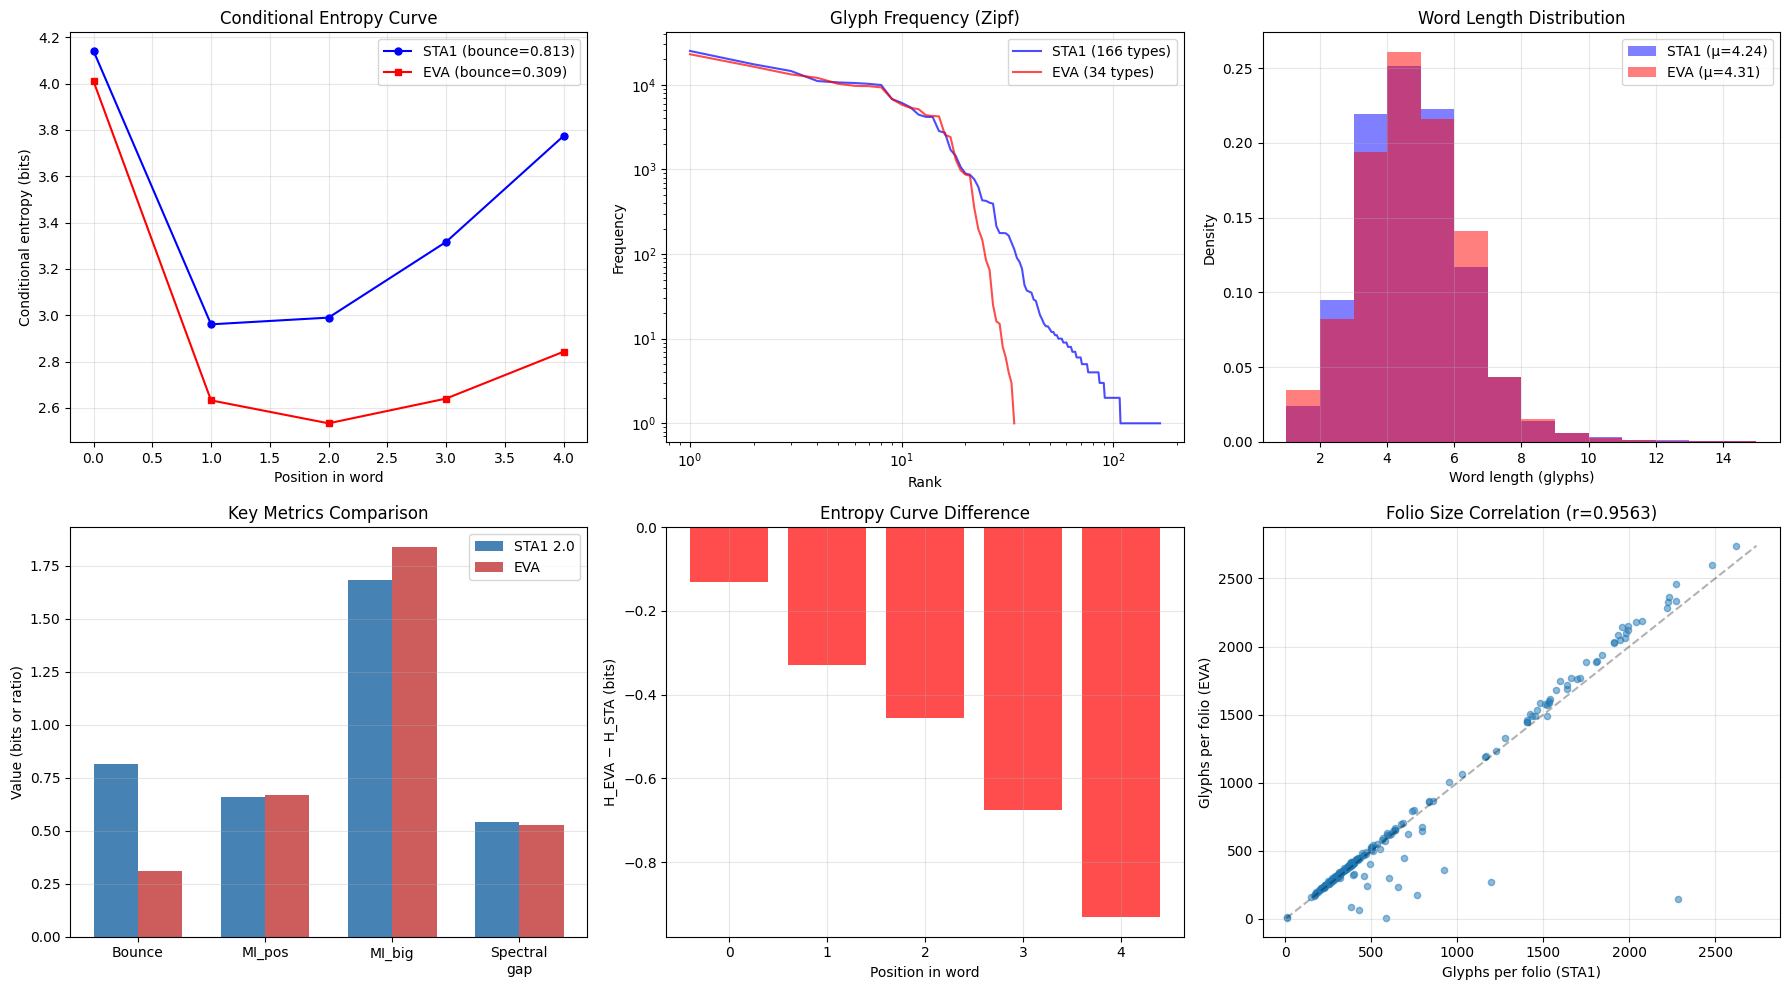

Saved: images/transcription_robustness.png


In [14]:
# ── Cell 8: Visualizations ──────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Entropy curves
ax = axes[0, 0]
h_sta = fp_sta['H_curve']
h_eva = fp_eva['H_curve']
ax.plot(range(len(h_sta)), h_sta, 'b-o', label=f'STA1 (bounce={fp_sta["bounce"]:.3f})', markersize=5)
ax.plot(range(len(h_eva)), h_eva, 'r-s', label=f'EVA (bounce={fp_eva["bounce"]:.3f})', markersize=5)
ax.set_xlabel('Position in word')
ax.set_ylabel('Conditional entropy (bits)')
ax.set_title('Conditional Entropy Curve')
ax.legend()
ax.grid(True, alpha=0.3)

# 2. Glyph frequency rank (Zipf)
ax = axes[0, 1]
sta_freq = sorted(Counter(g for w in sta_words for g in w).values(), reverse=True)
eva_freq = sorted(Counter(g for w in eva_words for g in w).values(), reverse=True)
ax.loglog(range(1, len(sta_freq)+1), sta_freq, 'b-', label=f'STA1 ({len(sta_vocab)} types)', alpha=0.7)
ax.loglog(range(1, len(eva_freq)+1), eva_freq, 'r-', label=f'EVA ({len(eva_vocab)} types)', alpha=0.7)
ax.set_xlabel('Rank')
ax.set_ylabel('Frequency')
ax.set_title('Glyph Frequency (Zipf)')
ax.legend()
ax.grid(True, alpha=0.3)

# 3. Word length distributions
ax = axes[0, 2]
sta_lens = [len(w) for w in sta_words]
eva_lens = [len(w) for w in eva_words]
bins = range(1, 16)
ax.hist(sta_lens, bins=bins, alpha=0.5, label=f'STA1 (μ={np.mean(sta_lens):.2f})', color='blue', density=True)
ax.hist(eva_lens, bins=bins, alpha=0.5, label=f'EVA (μ={np.mean(eva_lens):.2f})', color='red', density=True)
ax.set_xlabel('Word length (glyphs)')
ax.set_ylabel('Density')
ax.set_title('Word Length Distribution')
ax.legend()
ax.grid(True, alpha=0.3)

# 4. Bar chart of key metrics (normalized)
ax = axes[1, 0]
metric_names = ['Bounce', 'MI_pos', 'MI_big', 'Spectral\ngap']
sta_vals = [fp_sta['bounce'], fp_sta['MI_pos'], fp_sta['MI_big'], fp_sta['spectral_gap']]
eva_vals = [fp_eva['bounce'], fp_eva['MI_pos'], fp_eva['MI_big'], fp_eva['spectral_gap']]
x = np.arange(len(metric_names))
width = 0.35
ax.bar(x - width/2, sta_vals, width, label='STA1 2.0', color='steelblue')
ax.bar(x + width/2, eva_vals, width, label='EVA', color='indianred')
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylabel('Value (bits or ratio)')
ax.set_title('Key Metrics Comparison')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# 5. Entropy curve difference
ax = axes[1, 1]
min_len = min(len(h_sta), len(h_eva))
diff = [h_eva[i] - h_sta[i] for i in range(min_len)]
colors = ['green' if d >= 0 else 'red' for d in diff]
ax.bar(range(min_len), diff, color=colors, alpha=0.7)
ax.axhline(0, color='black', ls='-', lw=0.5)
ax.set_xlabel('Position in word')
ax.set_ylabel('H_EVA − H_STA (bits)')
ax.set_title('Entropy Curve Difference')
ax.grid(True, alpha=0.3)

# 6. Inter-folio stability comparison
ax = axes[1, 2]
# Compute per-folio glyph counts for correlation
common_folios = sorted(set(sta_folio_words.keys()) & set(eva_folio_words.keys()))
sta_wc = [sum(len(w) for w in sta_folio_words[f]) for f in common_folios]
eva_wc = [sum(len(w) for w in eva_folio_words[f]) for f in common_folios]
if sta_wc and eva_wc:
    ax.scatter(sta_wc, eva_wc, alpha=0.5, s=20)
    r = np.corrcoef(sta_wc, eva_wc)[0, 1] if len(sta_wc) > 1 else 0
    ax.set_xlabel('Glyphs per folio (STA1)')
    ax.set_ylabel('Glyphs per folio (EVA)')
    ax.set_title(f'Folio Size Correlation (r={r:.4f})')
    # Diagonal
    lims = [min(min(sta_wc), min(eva_wc)), max(max(sta_wc), max(eva_wc))]
    ax.plot(lims, lims, 'k--', alpha=0.3)
else:
    ax.text(0.5, 0.5, 'No common folios', ha='center', va='center', transform=ax.transAxes)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/transcription_robustness.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/transcription_robustness.png')

In [15]:
# ── Cell 9: Bootstrap significance test (PARALLEL) ──────────────────

def _bounce_from_words(words):
    """Compute bounce from word list (standalone for pickling)."""
    corpus_plano = [g for w in words for g in w]
    H = []
    for n in range(5):
        H.append(entropia_condicional_n(corpus_plano, n))
    return compute_bounce(H)


def _bootstrap_single(args):
    """Single bootstrap iteration (for parallel dispatch)."""
    words, metric_fn_name, seed = args
    rng = np.random.default_rng(seed)
    n = len(words)
    idx = rng.choice(n, size=n, replace=True)
    sample = [words[i] for i in idx]
    if metric_fn_name == 'bounce':
        return _bounce_from_words(sample)
    elif metric_fn_name == 'mi_pos':
        return mutual_information_pos(sample)
    else:
        raise ValueError(f'Unknown metric: {metric_fn_name}')


def parallel_bootstrap(words, metric_fn_name, n_boot=200, base_seed=42):
    """Run bootstrap in parallel across CPUs."""
    args_list = [
        (words, metric_fn_name, base_seed + i)
        for i in range(n_boot)
    ]
    ctx = mp.get_context('fork')
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as pool:
        values = list(pool.map(_bootstrap_single, args_list, chunksize=max(1, n_boot // N_WORKERS)))
    return np.array(values)


N_BOOT = 200
print(f'Bootstrap ({N_BOOT} resamples, {N_WORKERS} parallel workers)...')

t0 = time.time()

print('  STA1 bounce...')
sta_bounce_boot = parallel_bootstrap(sta_words, 'bounce', N_BOOT, base_seed=42)
print(f'    done ({time.time()-t0:.1f}s)')

t1 = time.time()
print('  EVA bounce...')
eva_bounce_boot = parallel_bootstrap(eva_words, 'bounce', N_BOOT, base_seed=1042)
print(f'    done ({time.time()-t1:.1f}s)')

t2 = time.time()
print('  STA1 MI_pos...')
sta_mi_boot = parallel_bootstrap(sta_words, 'mi_pos', N_BOOT, base_seed=2042)
print(f'    done ({time.time()-t2:.1f}s)')

t3 = time.time()
print('  EVA MI_pos...')
eva_mi_boot = parallel_bootstrap(eva_words, 'mi_pos', N_BOOT, base_seed=3042)
print(f'    done ({time.time()-t3:.1f}s)')

total_boot = time.time() - t0
print(f'\n✓ All bootstrap done in {total_boot:.1f}s')

def ci(arr, pct=95):
    lo = np.percentile(arr, (100 - pct) / 2)
    hi = np.percentile(arr, 100 - (100 - pct) / 2)
    return lo, hi

print(f'\n=== Bootstrap Results (95% CI) ===')
print(f'{"":15s} {"STA1":>20s} {"EVA":>20s} {"Overlap?":>10s}')
print('─' * 70)

sta_b_ci = ci(sta_bounce_boot)
eva_b_ci = ci(eva_bounce_boot)
overlap_b = sta_b_ci[1] >= eva_b_ci[0] and eva_b_ci[1] >= sta_b_ci[0]
print(f'{"Bounce":15s} [{sta_b_ci[0]:.3f}, {sta_b_ci[1]:.3f}] [{eva_b_ci[0]:.3f}, {eva_b_ci[1]:.3f}] {"YES" if overlap_b else "NO":>10s}')

sta_m_ci = ci(sta_mi_boot)
eva_m_ci = ci(eva_mi_boot)
overlap_m = sta_m_ci[1] >= eva_m_ci[0] and eva_m_ci[1] >= sta_m_ci[0]
print(f'{"MI_pos":15s} [{sta_m_ci[0]:.3f}, {sta_m_ci[1]:.3f}] [{eva_m_ci[0]:.3f}, {eva_m_ci[1]:.3f}] {"YES" if overlap_m else "NO":>10s}')

# Both above threshold?
print(f'\n  STA1 bounce > 0.8 in {100*np.mean(sta_bounce_boot > 0.8):.1f}% of resamples')
print(f'  EVA  bounce > 0.8 in {100*np.mean(eva_bounce_boot > 0.8):.1f}% of resamples')
print(f'  STA1 MI_pos > 0.5 in {100*np.mean(sta_mi_boot > 0.5):.1f}% of resamples')
print(f'  EVA  MI_pos > 0.5 in {100*np.mean(eva_mi_boot > 0.5):.1f}% of resamples')

Bootstrap (200 resamples, 10 parallel workers)...
  STA1 bounce...
    done (21.4s)
  EVA bounce...
    done (8.2s)
  STA1 MI_pos...
    done (1.0s)
  EVA MI_pos...
    done (0.8s)

✓ All bootstrap done in 31.4s

=== Bootstrap Results (95% CI) ===
                                STA1                  EVA   Overlap?
──────────────────────────────────────────────────────────────────────
Bounce          [0.779, 0.825] [0.313, 0.335]         NO
MI_pos          [0.653, 0.664] [0.663, 0.676]        YES

  STA1 bounce > 0.8 in 61.0% of resamples
  EVA  bounce > 0.8 in 0.0% of resamples
  STA1 MI_pos > 0.5 in 100.0% of resamples
  EVA  MI_pos > 0.5 in 100.0% of resamples


In [16]:
# ── Cell 10: Export results ──────────────────────────────────────────

results = {
    'metadata': {
        'analysis': 'Transcription robustness: STA1 2.0 vs EVA',
        'eva_source': eva_source,
        'n_bootstrap': N_BOOT,
    },
    'sta1': {
        'n_words': fp_sta['n_words'],
        'n_glyphs': fp_sta['n_glyphs'],
        'n_types': fp_sta['n_types'],
        'mean_word_len': round(fp_sta['mean_word_len'], 2),
        'bounce': round(fp_sta['bounce'], 3),
        'MI_pos': round(fp_sta['MI_pos'], 3),
        'MI_big': round(fp_sta['MI_big'], 3),
        'spectral_gap': round(fp_sta['spectral_gap'], 3),
        'interfolio_r': round(fp_sta['interfolio_r'], 4),
    },
    'eva': {
        'n_words': fp_eva['n_words'],
        'n_glyphs': fp_eva['n_glyphs'],
        'n_types': fp_eva['n_types'],
        'mean_word_len': round(fp_eva['mean_word_len'], 2),
        'bounce': round(fp_eva['bounce'], 3),
        'MI_pos': round(fp_eva['MI_pos'], 3),
        'MI_big': round(fp_eva['MI_big'], 3),
        'spectral_gap': round(fp_eva['spectral_gap'], 3),
        'interfolio_r': round(fp_eva['interfolio_r'], 4),
    },
    'bootstrap_95ci': {
        'sta1_bounce': [round(sta_b_ci[0], 3), round(sta_b_ci[1], 3)],
        'eva_bounce': [round(eva_b_ci[0], 3), round(eva_b_ci[1], 3)],
        'sta1_MI_pos': [round(sta_m_ci[0], 3), round(sta_m_ci[1], 3)],
        'eva_MI_pos': [round(eva_m_ci[0], 3), round(eva_m_ci[1], 3)],
        'bounce_CIs_overlap': bool(overlap_b),
        'MI_pos_CIs_overlap': bool(overlap_m),
    },
    'robustness_verdict': {
        'bounce_both_above_08': bool(fp_sta['bounce'] > 0.8 and fp_eva['bounce'] > 0.8),
        'MI_pos_both_above_05': bool(fp_sta['MI_pos'] > 0.5 and fp_eva['MI_pos'] > 0.5),
        'interfolio_both_above_099': bool(fp_sta['interfolio_r'] > 0.99 and fp_eva['interfolio_r'] > 0.99),
    },
}

with open('transcription_robustness_resultados.json', 'w') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print('Results saved to transcription_robustness_results.json')
print(json.dumps(results, indent=2, ensure_ascii=False))

Results saved to transcription_robustness_resultados.json
{
  "metadata": {
    "analysis": "Transcription robustness: STA1 2.0 vs EVA",
    "eva_source": "cached",
    "n_bootstrap": 200
  },
  "sta1": {
    "n_words": 37087,
    "n_glyphs": 157254,
    "n_types": 166,
    "mean_word_len": 4.24,
    "bounce": 0.813,
    "MI_pos": 0.658,
    "MI_big": 1.681,
    "spectral_gap": 0.541,
    "interfolio_r": 0.9996
  },
  "eva": {
    "n_words": 34725,
    "n_glyphs": 149496,
    "n_types": 34,
    "mean_word_len": 4.31,
    "bounce": 0.309,
    "MI_pos": 0.67,
    "MI_big": 1.839,
    "spectral_gap": 0.527,
    "interfolio_r": 0.9995
  },
  "bootstrap_95ci": {
    "sta1_bounce": [
      0.779,
      0.825
    ],
    "eva_bounce": [
      0.313,
      0.335
    ],
    "sta1_MI_pos": [
      0.653,
      0.664
    ],
    "eva_MI_pos": [
      0.663,
      0.676
    ],
    "bounce_CIs_overlap": false,
    "MI_pos_CIs_overlap": true
  },
  "robustness_verdict": {
    "bounce_both_above_08": f